# SEMI MS4, métrica y desempeño

**Equipo 39 · Proyecto Integrador MNA · Avance 3**

Esta parte presenta el tercer modelo de referencia, la fórmula estándar SEMI MS4, define la métrica con la que se comparan los tres métodos y evalúa su desempeño en las mismas 220 corridas. No entrena nada: lee los resultados guardados de los tres métodos y se ejecuta en segundos.

**En tres frases:**
1. SEMI MS4 calcula E con una fórmula cerrada a partir de la primera frecuencia del voladizo; reproduce el ejemplo publicado por NIST (65.34 GPa) y, con anclaje perfecto, se desvía solo 0.02 % por el redondeo de su constante.
2. Los tres métodos se comparan con el error relativo con signo en E, resumido por su mediana (sesgo) y su rango intercuartílico (dispersión) sobre 10 semillas, junto con la tasa de éxito y el tiempo de cómputo.
3. Los tres cumplen el desempeño mínimo fijado en el plan (error menor a 1 % sin ruido y diferencias con SEMI MS4 menores que su incertidumbre, ≈ 4.8 %); cuando el anclaje cede, los tres heredan casi el mismo sesgo (hasta −18 %), y la PINN y la inversión clásica lo reducen como mucho 1.6 puntos al usar tres modos: ese es el piso que deben mejorar las siguientes etapas.

### Contenido de esta parte

1. [El algoritmo: SEMI MS4](#3.1-El-algoritmo:-SEMI-MS4)
2. [La métrica](#3.2-La-métrica)
3. [Verificación sin ruido](#3.3-Verificación-sin-ruido)
4. [Desempeño en las celdas principales](#3.4-Desempeño-en-las-celdas-principales)
5. [Curva de aprendizaje](#3.5-Curva-de-aprendizaje)
6. [Conclusiones](#3.6-Conclusiones)

In [1]:
import sys
from pathlib import Path

# Busca la raíz del repositorio subiendo desde la carpeta actual
RAIZ = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "src" / "pinn_mems").is_dir())
sys.path.insert(0, str(RAIZ / "src"))

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from pinn_mems import metricas
from pinn_mems.nist.semi_ms4 import CONFIG, ejemplo_marshall, hash_metodo

pd.set_option("display.float_format", lambda v: f"{v:.3g}")
METODOS = list(metricas.COLORES)  # SEMI MS4, inversión clásica y PINN, siempre en este orden y color
REFERENCIA = {"m0": 0.0, "m1_s1": -1.0, "m1_s3": -5.0, "m1_s5": -15.0}  # sesgo de la fórmula estándar por caso, en %

## 3.1 El algoritmo: SEMI MS4

La norma SEMI MS4 (hoja YM.1 de NIST) estima el módulo de Young de un voladizo con su primera frecuencia de resonancia:

$$E = 38.330\,\rho\,\frac{f_1^2 L^4}{t^2}, \qquad f_1 = \frac{\omega_1}{2\pi}$$

donde $\rho$ es la densidad, $L$ la longitud, $t$ el espesor y $f_1$ la primera frecuencia en hertz. La fórmula sale de la ecuación de la viga ideal en voladizo con anclaje perfecto: la constante es $48\pi^2/\lambda_1^4$ con $\lambda_1 = 1.8751$, cuyo valor es 38.321; la norma la redondea a 38.330, lo que da un sesgo fijo de +0.02 %.

**Qué usa y qué no.** Solo la primera frecuencia de cada voladizo. No usa las formas modales, ni los modos 2 y 3, ni la biempotrada; por eso da el mismo resultado con 1 o con 3 modos y no estima σ₀. Con k = 3 promedia las estimaciones de los dos voladizos (300 y 200 µm).

**Por qué es apropiado como referencia.** Es el procedimiento estándar de la industria y de NIST, no tiene parámetros que ajustar y no puede sobreajustar: cualquier método más elaborado debe, como mínimo, igualarlo. Además comparte la física ideal (L0) con la inversión clásica y con la PINN, así que mide el sesgo de esa física sin la influencia de un optimizador.

La implementación reproduce el ejemplo publicado de un voladizo de 300 µm:

In [2]:
ej = ejemplo_marshall()
print(f"E = {ej['E_GPa']:.2f} GPa (publicado: 65.34 GPa)")
print(f"Incertidumbre combinada u_c(E) = {ej['u_cE_GPa']:.2f} GPa (publicado: 3.2 GPa)")
nombres = {"u_thick": "espesor", "u_rho": "densidad", "u_L": "longitud", "u_freq": "frecuencia",
           "u_fresol": "resolución de frecuencia", "u_damp": "amortiguamiento"}
display(pd.Series(ej["componentes_GPa"]).rename(nombres).to_frame("contribución a u_c(E) [GPa]"))

E = 65.34 GPa (publicado: 65.34 GPa)
Incertidumbre combinada u_c(E) = 3.14 GPa (publicado: 3.2 GPa)


,contribución a u_c(E) [GPa]
espesor,2.76
densidad,1.49
longitud,0.174
frecuencia,0.027
resolución de frecuencia,0.0018
amortiguamiento,0.0004


El valor de E coincide con el publicado. La incertidumbre difiere en menos de 2 % y la conclusión es la misma: domina el espesor, que entra al cuadrado en la fórmula. En los datos sintéticos el espesor es conocido, así que la incertidumbre que se evalúa en lo que sigue es la del ruido de medición y la del modelo de anclaje.

## 3.2 La métrica

La variable objetivo es E, así que la métrica principal es su **error relativo con signo** en cada corrida:

$$e = \frac{\hat{E} - E}{E}$$

donde $\hat{E}$ es el estimado y $E$ el valor verdadero (70 GPa). Por cada celda (caso, k y número de modos) se resume sobre las 10 semillas con:

| Métrica | Definición | Por qué |
|---|---|---|
| **Sesgo** | Mediana de $e$, en % | Con signo, porque la pregunta es si los métodos subestiman E cuando el anclaje cede. La mediana no se mueve por una semilla atípica |
| **Dispersión** | Rango intercuartílico (IQR) de $e$, en % | Separada del sesgo, porque un método puede ser preciso y estar sesgado; es lo que ocurre con la física ideal cuando el anclaje cede |
| **Tasa de éxito** | Fracción de corridas que convergen y tienen error menor a 50 % | Un método que a veces no converge no sirve como referencia aunque su mediana sea buena |
| **Costo** | Tiempo de cómputo mediano por corrida | Decide si un método escala a la matriz completa |

**Por qué no otras métricas.** El RMSE o el error absoluto medio mezclan sesgo y dispersión en un solo número y pierden el signo; el porcentaje de error absoluto (MAPE) también pierde el signo; y el R² no tiene sentido cuando cada corrida estima un solo parámetro con un valor verdadero fijo.

**Métricas secundarias.** Con k = 3 también se reporta el error en σ₀ (solo la inversión clásica y la PINN lo estiman). La capacidad de generalizar se mide en las partes 1 y 2 con el error al predecir la frecuencia de vigas de longitudes que no entraron al ajuste.

Las corridas forman tres bloques: **verificación** (sin ruido), **principal** (con ruido, 15 puntos por estructura) y **curva de aprendizaje** (con ruido, 5 y 40 puntos).

In [3]:
todas = pd.concat([metricas.tabla(metricas.cargar(m)) for m in METODOS], ignore_index=True)
todas["bloque"] = np.select([todas["sin_ruido"], todas["N"] != 15], ["verificación", "curva de aprendizaje"], "principal")
todas["error_E_pct"] = 100 * todas["err_E"]
display(todas.groupby(["bloque", "metodo"]).size().unstack()[METODOS].rename(columns=metricas.NOMBRES))
print("Corridas fallidas:", int(todas["fallo"].sum()))

metodo,SEMI MS4,Inversión clásica,PINN
bloque,,,
curva de aprendizaje,20,20,20
principal,160,160,160
verificación,40,40,40


Corridas fallidas: 0


## 3.3 Verificación sin ruido

Con datos de anclaje perfecto y sin ruido, la física de los tres métodos es la correcta: el error debe ser prácticamente cero. Cualquier diferencia mide el error numérico propio de cada método.

In [4]:
verificacion = todas[todas["bloque"] == "verificación"].groupby("metodo").agg(
    corridas=("fallo", "size"),
    error_max_E_pct=("err_E", lambda x: 100 * x.abs().max()),
    error_max_sigma0_pct=("err_sigma0", lambda x: 100 * x.abs().max()),
    tasa_exito=("fallo", lambda x: 1 - x.mean()),
)
display(verificacion.loc[METODOS].rename(index=metricas.NOMBRES))

,corridas,error_max_E_pct,error_max_sigma0_pct,tasa_exito
metodo,,,,
SEMI MS4,40,0.0229,NaN,1
Inversión clásica,40,6.41e-06,2.16e-05,1
PINN,40,0.052,0.673,1


Los tres pasan la verificación. La inversión clásica recupera E sin error apreciable porque usa la misma física que generó los datos. SEMI MS4 tiene el +0.02 % de su constante redondeada. La PINN tiene un error de aproximación de la red de 0.05 % en E y de 0.7 % en σ₀, muy por debajo de los sesgos que se miden después.

## 3.4 Desempeño en las celdas principales

La tabla muestra el sesgo en E de cada método en las 16 celdas principales, junto al **sesgo de referencia**: el que produce cada severidad del anclaje en la fórmula estándar (así se calibraron s1, s3 y s5).

In [5]:
principal = todas[todas["bloque"] == "principal"]
celdas = metricas.resumen(principal, por=("caso", "k", "n_modos", "metodo"))
sesgo = celdas["sesgo_E_pct"].unstack("metodo")[METODOS].rename(columns=metricas.NOMBRES)
sesgo.insert(0, "Sesgo de referencia", [REFERENCIA[c] for c in sesgo.index.get_level_values("caso")])
display(sesgo.style.format("{:.2f}").set_caption("Sesgo en E [%] por celda (mediana de 10 semillas)"))

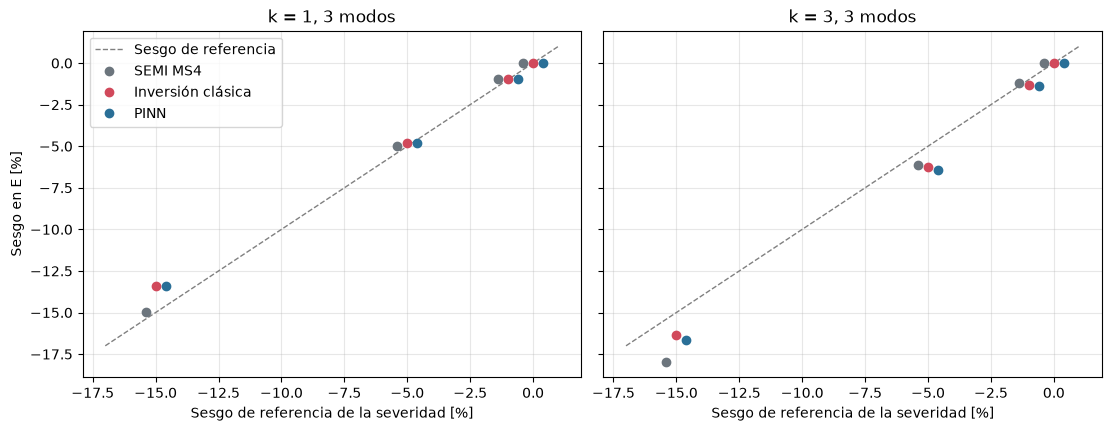

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4.2), sharey=True, constrained_layout=True)
for ax, k in zip(axes, (1, 3)):
    ax.plot([-17, 1], [-17, 1], color="gray", ls="--", lw=1, label="Sesgo de referencia")
    for j, m in enumerate(METODOS):
        r = celdas.xs((k, 3, m), level=("k", "n_modos", "metodo"))
        x = np.array([REFERENCIA[c] for c in r.index]) + (j - 1) * 0.4  # desplazados para que no se encimen
        ax.plot(x, r["sesgo_E_pct"], "o", color=metricas.COLORES[m], label=metricas.NOMBRES[m])
    ax.set(title=f"k = {k}, 3 modos", xlabel="Sesgo de referencia de la severidad [%]")
    ax.grid(alpha=0.3)
axes[0].set_ylabel("Sesgo en E [%]")
axes[0].legend()
plt.show()

Los tres métodos caen sobre la diagonal: **heredan el sesgo de la física ideal casi completo**. Con un solo voladizo y tres modos, la inversión clásica y la PINN lo reducen de −15.0 % a −13.4 % en s5 porque los modos superiores sienten el anclaje de otra forma; con k = 3 los tres quedan por debajo de la referencia (hasta −18 %), porque el voladizo de 200 µm es más sensible al anclaje que el de 300 µm. Ningún método L0 corrige el sesgo: solo puede hacerlo un modelo que represente el anclaje.

La dispersión entre semillas se ve mejor en las corridas individuales de M0:

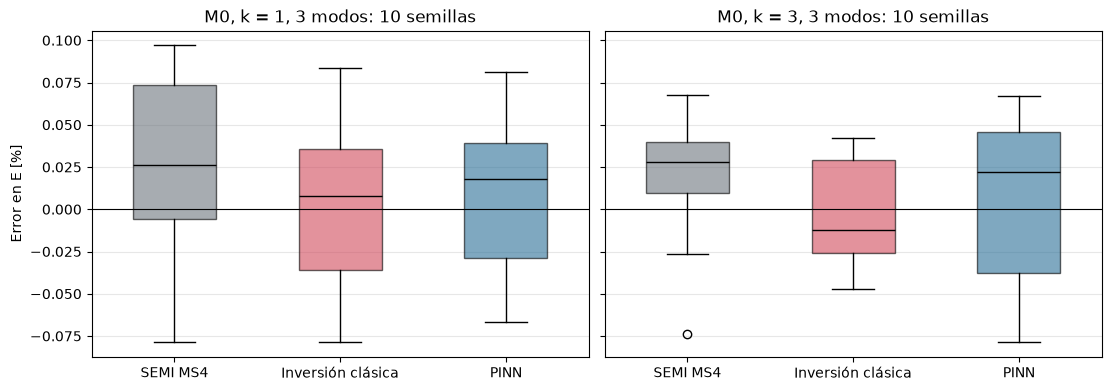

In [7]:
m0 = principal[(principal["caso"] == "m0") & (principal["n_modos"] == 3)]
fig, axes = plt.subplots(1, 2, figsize=(11, 3.8), sharey=True, constrained_layout=True)
for ax, k in zip(axes, (1, 3)):
    datos = [m0[(m0["k"] == k) & (m0["metodo"] == m)]["error_E_pct"] for m in METODOS]
    cajas = ax.boxplot(datos, patch_artist=True, widths=0.5, medianprops={"color": "black"})
    ax.set_xticks(range(1, len(METODOS) + 1), [metricas.NOMBRES[m] for m in METODOS])
    for caja, m in zip(cajas["boxes"], METODOS):
        caja.set(facecolor=metricas.COLORES[m], alpha=0.6)
    ax.axhline(0, color="black", lw=0.8)
    ax.set(title=f"M0, k = {k}, 3 modos: 10 semillas")
    ax.grid(alpha=0.3, axis="y")
axes[0].set_ylabel("Error en E [%]")
plt.show()

**Criterio de desempeño mínimo.** Se fijó en el plan del proyecto antes de correr los métodos, con dos referencias externas:

1. **Mínimo técnico:** con anclaje perfecto y sin ruido, error en E menor a 1 % (el mismo que se exigió a la PINN contra el modelo de referencia) y 100 % de éxito en todas las corridas.
2. **Mínimo histórico:** con anclaje que cede, la diferencia de sesgo contra SEMI MS4 en la misma celda debe ser menor que la incertidumbre combinada de la propia norma, $u_c(E)/E \approx 4.8\%$ (sección 3.1): una diferencia menor no se puede distinguir con el método estándar. Es más estricto que la dispersión entre laboratorios del *round robin* de NIST (64.2 ± 9.3 GPa, unos 14 %).

La tabla resume el criterio, el costo y el sesgo en σ₀ de cada método:

In [8]:
U_NORMA = 100 * ej["u_cE_GPa"] / ej["E_GPa"]  # incertidumbre relativa de SEMI MS4, en %
print(f"Incertidumbre relativa de SEMI MS4: {U_NORMA:.1f} %")
semi = celdas.xs("semi_ms4", level="metodo")["sesgo_E_pct"]
filas = {}
for m in METODOS:
    c = celdas.xs(m, level="metodo")
    en_m1 = c.drop(index="m0", level="caso")
    error_sin_ruido = 100 * todas[(todas["bloque"] == "verificación") & (todas["metodo"] == m)]["err_E"].abs().max()
    tasa = 1 - todas[todas["metodo"] == m]["fallo"].mean()
    diferencia = (en_m1["sesgo_E_pct"] - semi.loc[en_m1.index]).abs().max()
    filas[metricas.NOMBRES[m]] = {
        "error máx. sin ruido [%]": error_sin_ruido,
        "tasa de éxito": tasa,
        "|diferencia| máx. con SEMI MS4 en M1 [puntos]": diferencia,
        "cumple": bool(error_sin_ruido < 1 and tasa == 1 and diferencia < U_NORMA),
        "dispersión máx. [%]": c["dispersion_E_pct"].max(),
        "|sesgo σ₀| máx. en M1 [%]": en_m1["sesgo_sigma0_pct"].abs().max(),
        "tiempo mediano [s]": principal[principal["metodo"] == m]["tiempo_s"].median(),
    }
display(pd.DataFrame(filas).T)

Incertidumbre relativa de SEMI MS4: 4.8 %


,error máx. sin ruido [%],tasa de éxito,|diferencia| máx. con SEMI MS4 en M1 [puntos],cumple,dispersión máx. [%],|sesgo σ₀| máx. en M1 [%],tiempo mediano [s]
SEMI MS4,0.0229,1,0,True,0.079,NaN,0.163
Inversión clásica,6.41e-06,1,1.62,True,0.079,24.7,0.134
PINN,0.052,1,1.58,True,0.0836,22.9,82


Los tres cumplen con amplio margen: el error sin ruido es al menos 20 veces menor que el mínimo técnico, y la mayor diferencia con SEMI MS4 (1.6 puntos, a favor de los métodos que usan tres modos) es tres veces menor que la incertidumbre de la norma. Con anclaje que cede, los tres métodos son equivalentes a la referencia. Sus diferencias están en lo que cada uno permite hacer después:

- **SEMI MS4** es instantáneo (su tiempo es casi todo generar los datos de la corrida), pero solo usa una frecuencia y no estima σ₀.
- **La inversión clásica** usa todas las mediciones, estima σ₀ y tarda menos de un segundo.
- **La PINN** da los mismos resultados con un costo unas 600 veces mayor (más de un minuto por corrida). Lo que justifica ese costo es que en las siguientes etapas puede relajar la física o agregarle términos sin cambiar de método.

El error en σ₀ crece mucho más que el de E cuando el anclaje cede (hasta +25 % en s5): el sesgo en E se compensa en parte con un σ₀ equivocado.

## 3.5 Curva de aprendizaje

¿Mejora la estimación de E con más puntos medidos por estructura? Se compara M0 con un voladizo y un modo con 5, 15 y 40 puntos (10 semillas por punto).

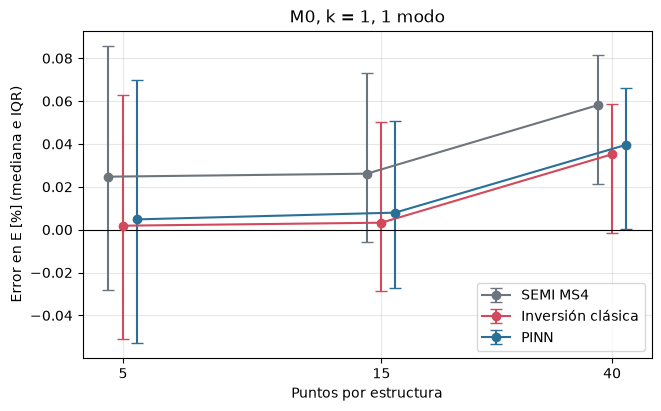

In [9]:
curva = todas[(todas["bloque"] != "verificación") & (todas["caso"] == "m0") & (todas["k"] == 1) & (todas["n_modos"] == 1)]
cuartiles = curva.groupby(["metodo", "N"])["error_E_pct"].quantile([0.25, 0.5, 0.75]).unstack()
fig, ax = plt.subplots(figsize=(6.5, 4), constrained_layout=True)
for j, m in enumerate(METODOS):
    q = cuartiles.loc[m]
    x = q.index * (1 + 0.06 * (j - 1))  # desplazados para que no se encimen
    ax.errorbar(x, q[0.5], yerr=[q[0.5] - q[0.25], q[0.75] - q[0.5]], fmt="o-", capsize=4,
                color=metricas.COLORES[m], label=metricas.NOMBRES[m])
ax.axhline(0, color="black", lw=0.8)
ax.set_xscale("log")
ax.set_xticks([5, 15, 40], ["5", "15", "40"])
ax.minorticks_off()
ax.set(xlabel="Puntos por estructura", ylabel="Error en E [%] (mediana e IQR)", title="M0, k = 1, 1 modo")
ax.legend()
ax.grid(alpha=0.3)
plt.show()

Con 5 a 40 puntos el sesgo de los tres métodos se mantiene por debajo de 0.06 % y la dispersión baja de 0.11 % a 0.06 %. SEMI MS4 no usa las formas: sus cambios con N vienen solo de que cada N sortea otro ruido de frecuencia. Que la inversión clásica y la PINN sigan exactamente la misma pauta muestra que **su estimación de E la fija la frecuencia medida**, no el número de puntos de la forma. Medir más puntos no compra precisión en E con la física ideal; las formas sirven para separar E de otros parámetros (σ₀ y, en las siguientes etapas, el anclaje).

## 3.6 Conclusiones

- **Métrica:** el error relativo con signo en E, resumido en sesgo (mediana) y dispersión (IQR) sobre 10 semillas, separa lo que importa en este problema: los métodos L0 son precisos (dispersión ≤ 0.08 %) pero se sesgan cuando el anclaje cede.
- **Desempeño:** con anclaje perfecto los tres métodos tienen |sesgo| ≤ 0.03 %, dispersión ≤ 0.08 % y 100 % de éxito en las 660 corridas. Con anclaje que cede los tres heredan el sesgo de la física ideal (−1 %, −5 % y −15 % a −18 % según la severidad) y difieren de SEMI MS4 en 1.6 puntos como máximo, muy por debajo de la incertidumbre de la norma (≈ 4.8 %): son equivalentes a ella. Con s5 ese sesgo iguala o supera incluso la dispersión entre laboratorios del *round robin* de NIST (≈ 14 %).
- **Costo:** SEMI MS4 y la inversión clásica tardan menos de un segundo por corrida; la PINN, más de un minuto.
- **Qué sigue:** SEMI MS4 es el piso que cualquier método debe igualar. Los modelos de las siguientes etapas (L1–L3) deben reducir el sesgo bajo M1, en E y en σ₀, sin perder la precisión que los tres baselines ya tienen en M0.